## 1. Objective

The goal of this notebook is to clean and standardize the corrupted dataset before using it for exploratory data analysis

During analysis of this dataset questions that will be answered are :

- Who uses AI, and for what purposes?

- Which AI tools are associated with the best reported outcomes?

- Is AI usage intensity associated with productivity?

- Which AI purposes are associated with the greatest time savings?

- Does perceived accuracy translate into satisfaction?

- Does spending more on AI correspond to better outcomes?

- Which users receive the greatest reported benefit relative to cost?

- Does AI usage have different associations with productivity across professions?

- What distinguishes users who recommend AI from those who do not?

- Are there signs of diminishing returns from increased AI usage?

- Which user segments have high usage but weak outcomes?

## 2. Setup

Import the libraries required for data manipulation and visualization

In [344]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import json

In [345]:
pd.set_option("display.max_columns", None)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    font_scale=1.05,
)

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.titlepad": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

## 3. Load and Inspect the Dataset

In [346]:
df=pd.read_csv("./data/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

In [347]:
print(f'dataset shape: {df.shape}')

dataset shape: (300, 19)


In [348]:
df.sample(5, random_state=42)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
203,U0163,48,Other,Australia,Professional,Master's,Research Analyst,5903,ChatGPT,Research,1.6,Literature review synthesis using AI-powered d...,20,5.2,3.0,7.0,6.5,9.7,Yes
266,U0109,17,F,Canada,Student,High School,Computer Science Student,595,ChatGPT,Coding,8,"Debugging Python code with AI assistance, gene...",0,7.4,3.0,7.0,15.8,6.1,Yes
152,U0045,36,Male,India,Professional,Bachelor's,Senior Software Developer,987,ChatGPT,Coding,1.5,Code review and optimization using AI assistan...,0,4.2,3.0,6.0,1.8,7.6,Maybe
9,U0167,40,male,india,Professional,High School,NaN,1595,ChatGPT,Writing,1.7,"Email copywriting, Social media post creation,...",10,NaN,2.0,5.0,7.5,9.4,Maybe
233,U0013,NaN,Male,Canada,Professional,HS,Junior Web Developer,3779,ChatGPT,Coding,5.7,Writing JavaScript code with AI code completio...,0,6.7,2.0,5.0,13,6.6,Maybe


## 4. Initial Data Audit

This **audity** dataframe shows missing values and their overall size in their respective column  

In [349]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score           28

In [350]:
df.describe(include='all')

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
count,300,277,290,290,300,287,285,290,289,287,293,282,288,284.000000,285.000000,293.000000,290,291,295
unique,288,52,11,20,2,16,126,233,16,8,89,270,12,NaN,NaN,NaN,133,93,3
top,U0138,23,Male,India,Student,Bachelor's,English Literature Student,0,ChatGPT,Coding,1.5,Responding to customer inquiries via AI chatbo...,0,NaN,NaN,NaN,0,6.4,Yes
freq,2,26,122,42,158,71,24,33,113,70,13,2,145,NaN,NaN,NaN,8,13,178
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.230282,3.428070,6.146758,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.817193,0.855338,1.517805,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.600000,2.000000,3.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.900000,3.000000,5.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,4.000000,6.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.500000,4.000000,7.000000,NaN,NaN,NaN


In [351]:
audit = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean().mul(100).round(2),
    "unique": df.nunique()
}).sort_values("missing_%", ascending=False)

audit

,dtype,missing,missing_%,unique
Age,str,23,7.67,52
Tasks_Performed,str,18,6.00,270
Productivity_Score,float64,16,5.33,73
Profession,str,15,5.00,126
Accuracy_Rating,float64,15,5.00,4
AI_Purpose,str,13,4.33,8
Education_Level,str,13,4.33,16
Monthly_AI_Cost,str,12,4.00,12
AI_Tool,str,11,3.67,16
Time_Saved_Hours_Per_Week,str,10,3.33,133


In [352]:
initial_shape = df.shape
initial_missing = df.isna().sum().sum()

## 5. Data Cleaning

In [353]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score           28

### 5.1 Age

In [354]:
df['Age']=df['Age'].astype(str).str.extract(r'(\d+\.?\d*)').astype(float)

df['Age'] = np.floor(df['Age']).astype('Int16')

### 5.2 Gender

In [355]:
df['Gender'].str.lower().unique()

<StringArray>
['male', 'female', nan, 'm', 'f', 'other', 'non-binary']
Length: 7, dtype: str

In [356]:
df['Gender']=df['Gender'].str.lower().replace(
    {
        'm':'male',
        'f':'female',
        'non-binary':"other"
    }
)

df['Gender'] = df['Gender'].astype('category')

### 5.3 Country

In [357]:
df['Country'].str.lower().unique()

<StringArray>
[          'united kingdom',            'united states',
                   'canada',                   'brazil',
                   'france',              'philippines',
                    'india',                 'pakistan',
                'australia',                    'kenya',
                  'nigeria',                  'germany',
                        nan,                     'u.k.',
 'united states of america']
Length: 15, dtype: str

In [358]:
df['Country'] = df['Country'].str.lower().replace(
    {
        'u.k' : 'united kingdom',
        'united states':'usa',
        'united states of america':'usa'
    }
)

df['Country']=df['Country'].astype('category')

### 5.4 User Type

In [359]:
df['User_Type'].str.lower().unique()

<StringArray>
['professional', 'student']
Length: 2, dtype: str

In [360]:
df['User_Type']=df['User_Type'].astype('category')

### 5.5 Education Level

In [361]:
df['Education_Level'].str.lower().unique()

<StringArray>
[         'master's',        'bachelor's',                 nan,
     'undergraduate',       'high school',           'diploma',
               'phd',            'ba/bsc',            'ma/msc',
             'ph.d.',           'masters',   'master's degree',
 'bachelor's degree',         'undergrad',         'bachelors',
                'hs']
Length: 16, dtype: str

In [362]:
df['Education_Level']=df['Education_Level'].str.lower().replace(
    {
        "master's": "Master's",
        "masters": "Master's",
        "master's degree": "Master's",
        "ma/msc": "Master's",
        
        "bachelor's": "Bachelor's",
        "bachelors": "Bachelor's",
        "bachelor's degree": "Bachelor's",
        "undergraduate": "Bachelor's",
        "undergrad": "Bachelor's",
        "ba/bsc": "Bachelor's",
        
        "high school": "High School",
        "hs": "High School",
        "diploma": "High School",
        
        "phd": "PhD",
        "ph.d.": "PhD"
    }
)

df['Education_Level']=df['Education_Level'].astype('category')

### 5.6 Profession

In [363]:
df['Profession'].str.lower().unique()

<StringArray>
[                                'business analyst',
                      'customer support specialist',
                         'computer science student',
  'desenvolvedora de software / software developer',
                                  'biology student',
                       'business analytics student',
                           'développeur full stack',
                     'social media content creator',
                 'digital media production student',
                                                nan,
 ...
          'softwareentwickler (software developer)',
               'projektmanagerin (project manager)',
                      'software support technician',
                       'desenvolvedora de software',
               'analyste de données / data analyst',
                               'research scientist',
 'academic research professor and technical writer',
                                'analista de dados',
                      'mult

In [364]:
role_mapping = {
    # --- Software Engineering & Development ---
    'desenvolvedora de software / software developer': 'Software Engineer',
    'développeur full stack': 'Software Engineer',
    'software developer': 'Software Engineer',
    'senior software engineer': 'Software Engineer',
    'engenheiro de software sênior / tech lead': 'Software Engineer',
    'senior software engineer / technical lead': 'Software Engineer',
    'desenvolvedor de software sênior': 'Software Engineer',
    'senior software engineer / ai solutions architect': 'Software Engineer',
    'senior software developer / softwareentwicklerin': 'Software Engineer',
    'junior software developer': 'Software Engineer',
    'senior software developer': 'Software Engineer',
    'desenvolvedora de sistemas júnior': 'Software Engineer',
    'junior web developer': 'Software Engineer',
    'softwareentwicklerin (software developer)': 'Software Engineer',
    'développeur logiciel (software developer)': 'Software Engineer',
    'développeur full stack junior': 'Software Engineer',
    'senior software engineer / ai systems developer': 'Software Engineer',
    'software developer (diploma qualified)': 'Software Engineer',
    'desenvolvedor de sistemas junior': 'Software Engineer',
    'softwareentwickler (software developer)': 'Software Engineer',
    'desenvolvedora de software': 'Software Engineer',
    'desenvolvedor de sistemas (systems developer)': 'Software Engineer',
    'software support technician': 'IT Support',
    
    # --- Data Science, AI & Analytics ---
    'business analyst': 'Business Analyst',
    'business analytics student': 'Student', # Or 'Data Analyst' if you prefer
    'research analyst': 'Data Analyst',
    'data analyst': 'Data Analyst',
    'data analytics manager': 'Data Analyst',
    'business intelligence analyst': 'Data Analyst',
    'data entry specialist': 'Data Entry',
    'data entry operator': 'Data Entry',
    'senior machine learning engineer': 'Data Scientist / ML',
    'senior data scientist': 'Data Scientist / ML',
    'analista de dados sênior': 'Data Analyst',
    'datenanalyst': 'Data Analyst',
    'research scientist / data analyst': 'Data Scientist / ML',
    'data analyst / business intelligence specialist': 'Data Analyst',
    'analyste de données / data analyst': 'Data Analyst',
    'analista de dados': 'Data Analyst',
    'research scientist': 'Research Scientist',
    'senior research scientist': 'Research Scientist',
    'pesquisador sênior em inteligência artificial e ciência de dados': 'Research Scientist',
    'research scientist/senior research officer': 'Research Scientist',
    'ai content strategist': 'AI Specialist',
    
    # --- Content, Writing & Marketing ---
    'social media content creator': 'Content Creator',
    'digital content creator': 'Content Creator',
    'content writer': 'Content Writer',
    'content strategy manager': 'Content Strategist',
    'social media content creator / digital marketer': 'Content Creator',
    'responsable de contenu digital': 'Content Strategist',
    'marketing communications officer': 'Marketing',
    'content marketing manager': 'Marketing',
    'digital content strategist': 'Content Strategist',
    'senior content strategist': 'Content Strategist',
    'content strategist & technical writer': 'Content Strategist',
    'content manager': 'Content Strategist',
    'content creator/gestor de conteúdo digital': 'Content Creator',
    'technical writer': 'Technical Writer',
    'digital content creator / social media manager': 'Content Creator',
    'content strategist': 'Content Strategist',
    'digital content writer': 'Content Writer',
    'academic research professor and technical writer': 'Technical Writer',
    'multimedia content producer': 'Content Creator',
    'digital marketing manager': 'Marketing',
    
    # --- Customer Support & Admin ---
    'customer support specialist': 'Customer Support',
    'customer service representative': 'Customer Support',
    'ai-powered customer support executive': 'Customer Support',
    'kundenservice-spezialistin / customer service specialist': 'Customer Support',
    'customer support manager': 'Customer Support',
    'ai customer support specialist': 'Customer Support',
    'especialista em atendimento ao cliente com ia': 'Customer Support',
    'customer experience manager': 'Customer Support',
    'customer support specialist / ai support operations manager': 'Customer Support',
    'ai customer success manager': 'Customer Support',
    'gerente de atendimento ao cliente': 'Customer Support',
    'kundenbetreuerin mit ki-unterstützung': 'Customer Support',
    'customer service executive': 'Customer Support',
    'customer support executive': 'Customer Support',
    'administrative assistant': 'Administrative',
    'administrative executive': 'Administrative',
    'assistente administrativo': 'Administrative',
    'projektmanagerin (project manager)': 'Project Manager',

    # --- Students (Grouped by Field) ---
    'computer science student': 'Student',
    'biology student': 'Student',
    'digital media production student': 'Student',
    'mechanical engineering student': 'Student',
    'software engineering student': 'Student',
    'english literature student': 'Student',
    'business administration student': 'Student',
    'engineering student': 'Student',
    'information technology student': 'Student',
    'artificial intelligence and machine learning student': 'Student',
    'digital media student': 'Student',
    'digital media and communications student': 'Student',
    'bioinformatics student': 'Student',
    'biotechnology student': 'Student',
    'environmental science student': 'Student',
    'artificial intelligence research student': 'Student',
    'molecular biology student': 'Student',
    'electronics engineering student': 'Student',
    'german literature student': 'Student',
    'machine learning research student': 'Student',
    'software development student': 'Student',
    'mathematics student': 'Student',
    'history student': 'Student',
    'data science student': 'Student',
    'digital marketing student': 'Student',
    'machine learning student': 'Student',
    'creative writing student': 'Student',
    'computer science phd student': 'Student',
    'theoretical physics student': 'Student',
    'biomedical science student': 'Student',
    'physics student': 'Student',
    'artificial intelligence & digital media student': 'Student',
    'german literature and comparative studies student': 'Student',
    'digital media & film production student': 'Student',
    'biomedical engineering student': 'Student',
    'psychology student': 'Student',
    'biotechnology phd student': 'Student',
    'electronics and communication engineering student': 'Student',
    'psychology research student': 'Student',
    'statistics student': 'Student',
    'literature student': 'Student',
    
    # --- Research (Non-Student) ---
    'research technician': 'Research',
    'research assistant': 'Research',
    'pesquisador de mercado': 'Research'
}

In [365]:
df['Profession']=df['Profession'].str.lower().replace(
    role_mapping
)

df['Profession']=df['Profession'].astype('category')

### 5.7 Monthly Income

In [366]:
df['Monthly_Income']=df['Monthly_Income'].astype(str).str.extract(r'(\d+\.?\d*)').astype('Int32')

In [367]:
df[(df['Monthly_Income']==0)].shape[1] # rows with income of 0 can be classified as nan

19

In [368]:
df['Monthly_Income']=df['Monthly_Income'].replace(0,np.nan)

In [369]:
df['Monthly_Income'].info()

<class 'pandas.Series'>
RangeIndex: 300 entries, 0 to 299
Series name: Monthly_Income
Non-Null Count  Dtype
--------------  -----
256 non-null    Int32
dtypes: Int32(1)
memory usage: 1.6 KB


### 5.8 AI Tools

In [370]:
df['AI_Tool'].str.lower().unique()

<StringArray>
[          'chatgpt',          'chat gpt',           'meta ai',
     'perplexity ai',            'claude', 'microsoft copilot',
     'google gemini',         'grammarly',          'deepseek',
                 nan,            'gemini',           'copilot']
Length: 12, dtype: str

In [371]:
df['AI_Tool']=df['AI_Tool'].str.lower().replace(
    {
    'chatgpt': 'ChatGPT',
    'chat gpt': 'ChatGPT',
    
    'google gemini': 'Google Gemini',
    'gemini': 'Google Gemini',
    

    'microsoft copilot': 'Microsoft Copilot',
    'copilot': 'Microsoft Copilot',
    
    'claude': 'Claude',
    
    'perplexity ai': 'Perplexity AI',
    
    'meta ai': 'Meta AI',

    'grammarly': 'Grammarly',
    'deepseek': 'DeepSeek'
}
)

df['AI_Tool'] = df['AI_Tool'].astype('category')

### 5.9 AI Purpose

In [372]:
df['AI_Purpose'].str.lower().unique()

<StringArray>
[     'office work', 'customer support',           'coding',
                nan,    'data analysis', 'content creation',
          'writing',         'research',         'studying']
Length: 9, dtype: str

In [373]:
df['AI_Purpose']=df['AI_Purpose'].str.lower().astype('category')

### 5.10 AI Usage Hours Per Day

In [374]:
df['AI_Usage_Hours_Per_Day']

0        2 hrs
1          5.7
2        1 hrs
3          1.7
4          4.1
        ...   
295        1.8
296        1.2
297        5.5
298    0.7 hrs
299        2.8
Name: AI_Usage_Hours_Per_Day, Length: 300, dtype: str

In [375]:
df['AI_Usage_Hours_Per_Day']=df['AI_Usage_Hours_Per_Day'].astype(str).str.extract(r'(\d+\.?\d*)').astype(float).round(2)

### 5.11 Tasks Performed

In [376]:
df['Tasks_Performed'].str.lower().sample(5, random_state=42)

203    literature review synthesis using ai-powered d...
266    debugging python code with ai assistance, gene...
152    code review and optimization using ai assistan...
9      email copywriting, social media post creation,...
233    writing javascript code with ai code completio...
Name: Tasks_Performed, dtype: str

In [377]:
standardized_tasks=dict()

with open('./standardized_tasks.json','r',encoding='utf-8') as file:
    standardized_tasks=json.load(file)

standardized_tasks[np.nan]='Uncategorized'

In [378]:
df['Tasks_Performed']=df['Tasks_Performed'].str.lower().replace(standardized_tasks)

df['Tasks_Performed']=df['Tasks_Performed'].astype('category')

### 5.12 Monthly AI Cost

In [379]:
df['Monthly_AI_Cost']=df['Monthly_AI_Cost'].astype(str).str.extract(r'(\d+\.?\d*)').astype('Int8')

In [380]:
df['Monthly_AI_Cost'].unique()

<IntegerArray>
[<NA>, 0, 20, 30, 10, 50, 25, 100]
Length: 8, dtype: Int8

### 5.13 , 5.14 , 5.15 Productivity Score , Accuracy Rating , Satisfaction Score

nothing to see here

### 5.16 Time Saved : hours per week

In [381]:
df['Time_Saved_Hours_Per_Week']=df['Time_Saved_Hours_Per_Week'].astype(str).str.extract(r'(\d+\.?\d*)').astype('float32').round(2)

### 5.17 Work or Study : Hours per Day

In [382]:
df['Work_or_Study_Hours_Per_Day']=df['Work_or_Study_Hours_Per_Day'].astype(str).str.extract(r'(\d+\.?\d*)').astype('float32').round(2)

### 5.18 Would Recommend

In [383]:
df['Would_Recommend'].str.lower().unique()

<StringArray>
['yes', 'no', 'maybe', nan]
Length: 4, dtype: str

In [384]:
df['Would_Recommend']=df['Would_Recommend'].str.lower().astype('category')

## Final dataset

In [385]:
print("Shape:", df.shape)

display(
    pd.DataFrame({
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "missing_%": df.isna().mean().mul(100).round(2),
        "unique": df.nunique()
    })
)

Shape: (300, 19)


,dtype,missing,missing_%,unique
User_ID,str,0,0.00,288
Age,Int16,23,7.67,42
Gender,category,10,3.33,3
Country,category,10,3.33,13
User_Type,category,0,0.00,2
Education_Level,category,13,4.33,4
Profession,category,15,5.00,18
Monthly_Income,Int32,44,14.67,230
AI_Tool,category,11,3.67,8
AI_Purpose,category,13,4.33,8


In [386]:
final_shape = df.shape
final_missing = df.isna().sum().sum()

print(f"Initial rows: {initial_shape[0]}")
print(f"Final rows:   {final_shape[0]}")
print(f"Rows removed: {initial_shape[0] - final_shape[0]}")

print(f"\nInitial missing values: {initial_missing}")
print(f"Final missing values:   {final_missing}")

Initial rows: 300
Final rows:   300
Rows removed: 0

Initial missing values: 204
Final missing values:   220


In [387]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   User_ID                      300 non-null    str     
 1   Age                          277 non-null    Int16   
 2   Gender                       290 non-null    category
 3   Country                      290 non-null    category
 4   User_Type                    300 non-null    category
 5   Education_Level              287 non-null    category
 6   Profession                   285 non-null    category
 7   Monthly_Income               256 non-null    Int32   
 8   AI_Tool                      289 non-null    category
 9   AI_Purpose                   287 non-null    category
 10  AI_Usage_Hours_Per_Day       293 non-null    float64 
 11  Tasks_Performed              300 non-null    category
 12  Monthly_AI_Cost              288 non-null    Int8    
 13  Productivity_Sco

## 6. Data Analysis

### Correlation

In [388]:
correlation_matrix=df.corr(numeric_only=True)

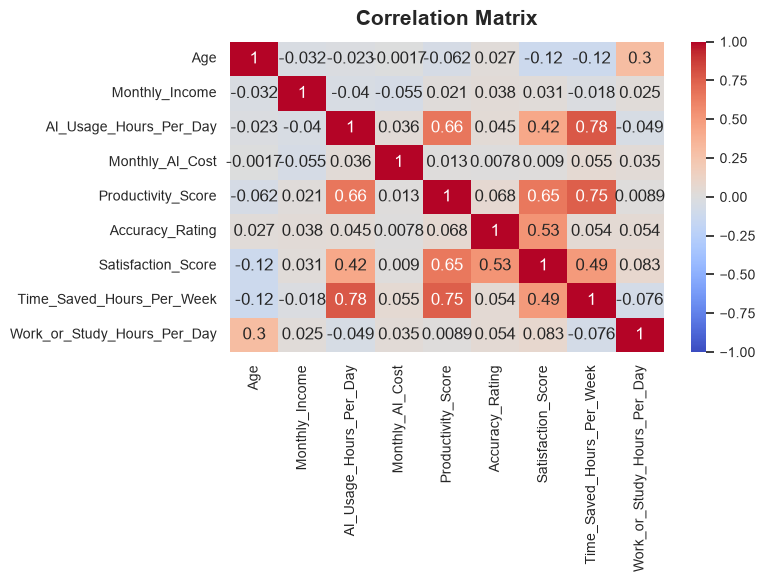

In [389]:
fig,ax = plt.subplots(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)

plt.title("Correlation Matrix")

plt.tight_layout()

In [390]:
df.sample(10).to_csv('./sample.csv')

### Q1 : Who uses AI, and for what purposes?

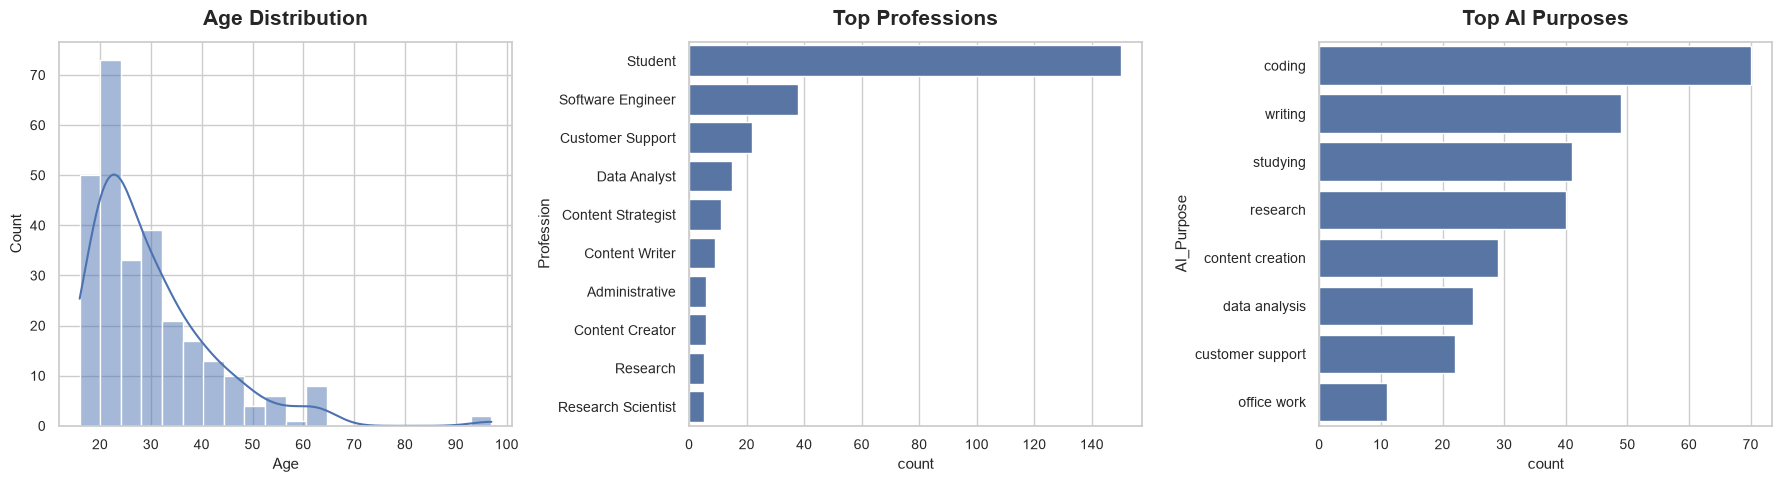

In [391]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    df['Age'].dropna(),
    bins=20,
    kde=True, 
    ax=axes[0]
).set_title('Age Distribution')

sns.countplot(
    y='Profession',
    data=df,
    order=df['Profession'].value_counts().index[:10],
    ax=axes[1]
    ).set_title('Top Professions')

sns.countplot(
    y='AI_Purpose',
    data=df, 
    order=df['AI_Purpose'].value_counts().index[:10], 
    ax=axes[2]
    ).set_title('Top AI Purposes')

plt.tight_layout()

### Q2 : Which AI tools are associated with the best reported outcomes?

In [392]:
outcomes = df.groupby('AI_Tool')[
    [
        'Productivity_Score', 
        'Satisfaction_Score', 
        'Accuracy_Rating', 
        'Time_Saved_Hours_Per_Week'
    ]
    ].mean().dropna()

print(outcomes.sort_values(by='Productivity_Score', ascending=False).head(5))

                   Productivity_Score  Satisfaction_Score  Accuracy_Rating  \
AI_Tool                                                                      
DeepSeek                     5.740000            6.333333         3.888889   
Microsoft Copilot            5.548485            6.305556         3.388889   
Claude                       5.293103            6.096774         3.370370   
ChatGPT                      5.217391            6.237288         3.358974   
Meta AI                      5.150000            6.100000         3.500000   

                   Time_Saved_Hours_Per_Week  
AI_Tool                                       
DeepSeek                            7.375000  
Microsoft Copilot                   6.831429  
Claude                              5.613793  
ChatGPT                             5.947059  
Meta AI                             4.790000  


Text(0.5, 1.0, 'Satisfaction Score by Top 10 AI Tools')

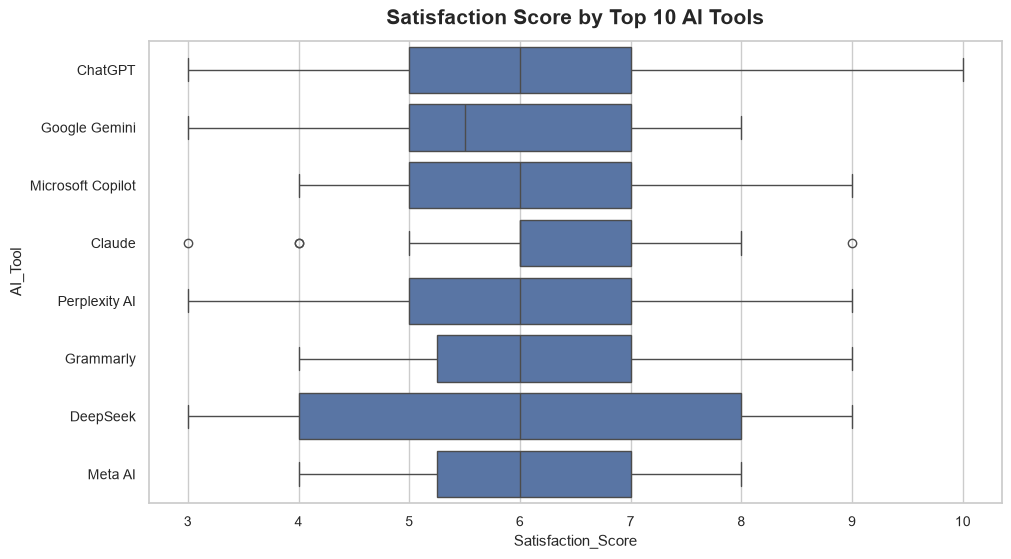

In [393]:
sns.boxplot(
    x='Satisfaction_Score', 
    y='AI_Tool', 
    data=df, 
    order=df['AI_Tool'].value_counts().index[:10]

)
plt.title("Satisfaction Score by Top 10 AI Tools")

### Q3 : Is AI usage intensity associated with productivity?

Text(0.5, 1.0, 'AI Usage Intensity vs. Productivity Score')

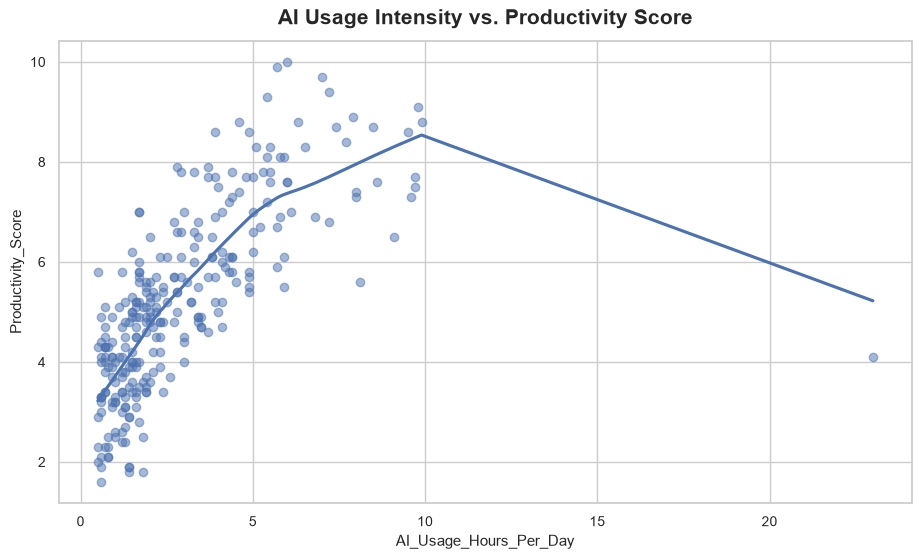

In [394]:
sns.regplot(
    x='AI_Usage_Hours_Per_Day', 
    y='Productivity_Score', 
    data=df, 
    scatter_kws={'alpha':0.5}, 
    lowess=True
)

plt.title("AI Usage Intensity vs. Productivity Score")

### Q4 : Which AI purposes are associated with the greatest time savings?

Text(0.5, 1.0, 'Time Saved by AI Purpose (Medians & Distributions)')

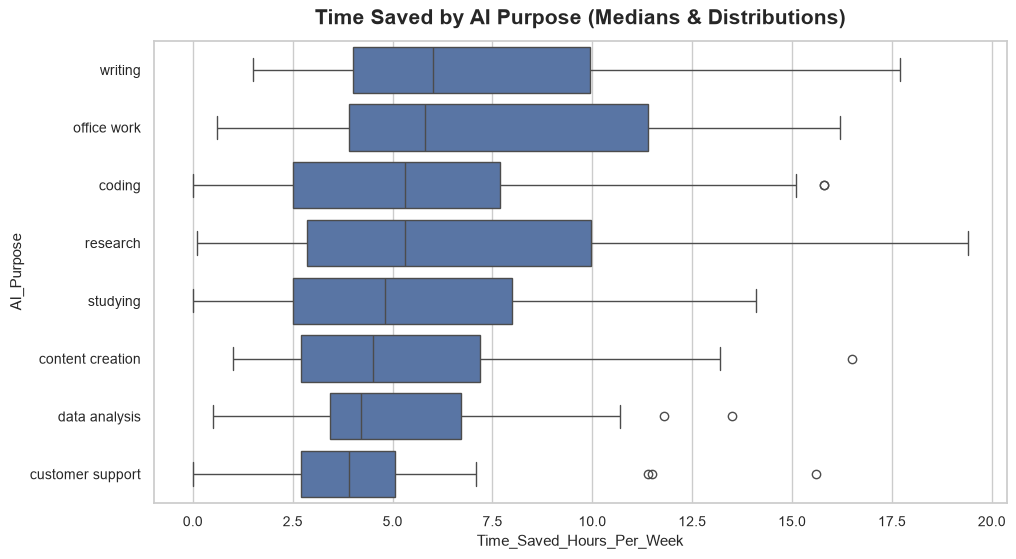

In [395]:
sns.boxplot(
    x='Time_Saved_Hours_Per_Week',
    y='AI_Purpose', 
    data=df, 
    order=df.groupby('AI_Purpose')['Time_Saved_Hours_Per_Week']
    .median()
    .sort_values(ascending=False).index[:10]
    )

plt.title("Time Saved by AI Purpose (Medians & Distributions)")

### Q5 : Does perceived accuracy translate into satisfaction?

Text(0.5, 1.0, 'Satisfaction Score Across Accuracy Ratings')

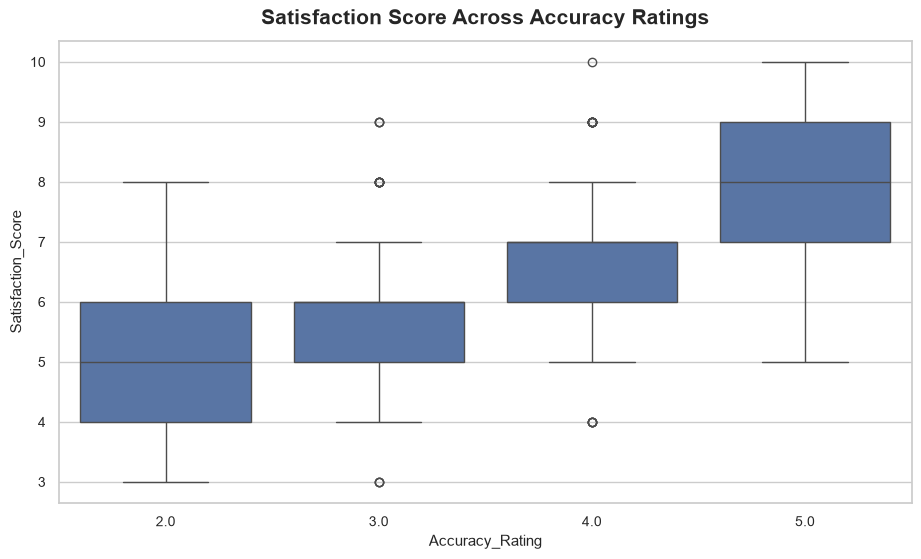

In [396]:
sns.boxplot(
    x='Accuracy_Rating', 
    y='Satisfaction_Score', 
    data=df
)

plt.title("Satisfaction Score Across Accuracy Ratings")

### Q6 : Does spending more on AI correspond to better outcomes?

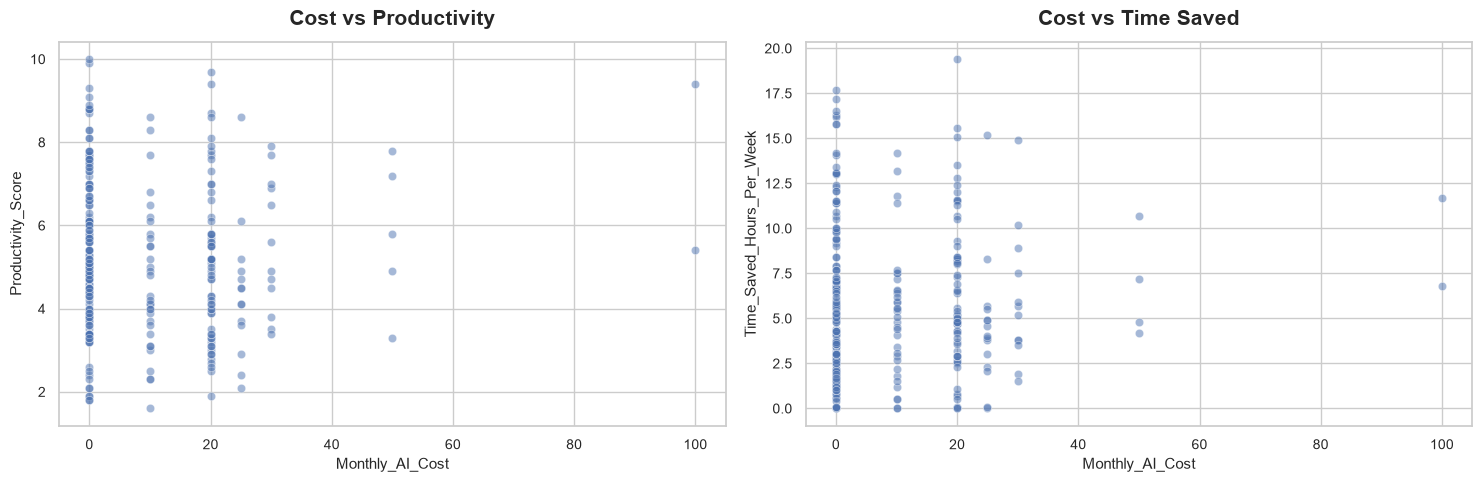

In [397]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    x='Monthly_AI_Cost', 
    y='Productivity_Score', 
    data=df, 
    alpha=0.5, 
    ax=axes[0]
).set_title('Cost vs Productivity')

sns.scatterplot(
    x='Monthly_AI_Cost', 
    y='Time_Saved_Hours_Per_Week', 
    data=df, 
    alpha=0.5, 
    ax=axes[1]
).set_title('Cost vs Time Saved')

plt.tight_layout()

### Q7 : Which users receive the greatest reported benefit relative to cost?

In [398]:
df['Value_Proxy'] = (df['Productivity_Score'] * df['Time_Saved_Hours_Per_Week']) / (df['Monthly_AI_Cost'] + 1)

top_value_users = df.nlargest(10, 'Value_Proxy')

print(top_value_users[['Profession', 'AI_Tool', 'Monthly_AI_Cost', 'Value_Proxy']])

             Profession        AI_Tool  Monthly_AI_Cost  Value_Proxy
188             Student      Grammarly                0   143.780002
78       Administrative        ChatGPT                0   142.560007
248             Student        ChatGPT                0   134.520006
250             Student        ChatGPT                0   129.000006
264             Student       DeepSeek                0   126.379998
96              Student  Google Gemini                0   121.830004
47   Content Strategist        ChatGPT                0   118.989994
266             Student        ChatGPT                0   116.920001
1      Customer Support        ChatGPT                0   112.859996
28              Student        ChatGPT                0   107.010002


### Q8 : Does AI usage have different associations with productivity across professions?

Text(0.5, 1.0, 'Usage vs Productivity Across Top 5 Professions')

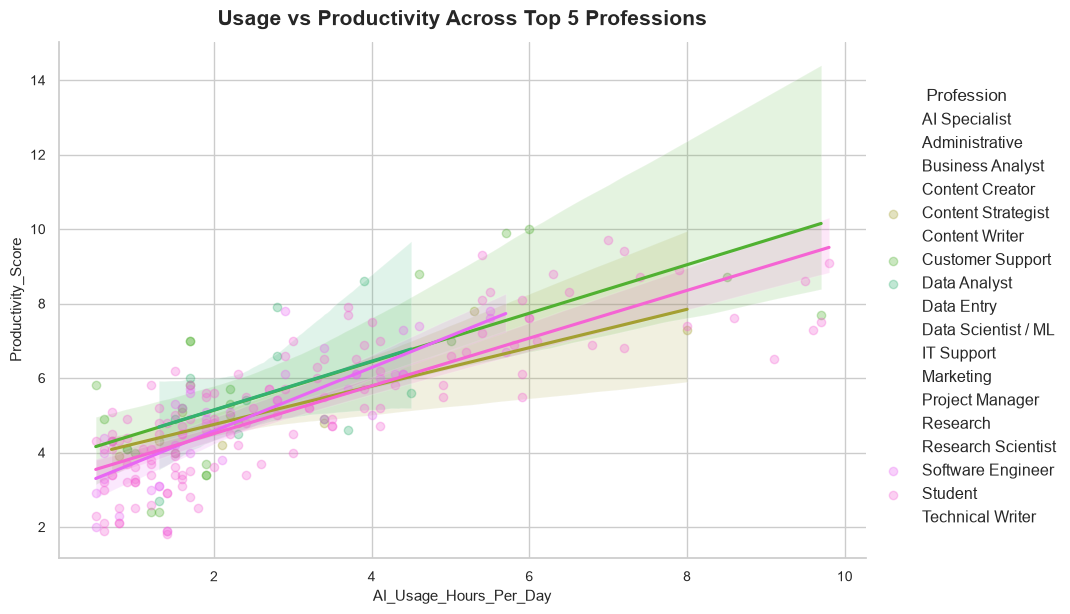

In [399]:
top_professions = df['Profession'].value_counts().index[:5]

sns.lmplot(
    x='AI_Usage_Hours_Per_Day', 
    y='Productivity_Score',
    hue='Profession', 
    data=df[df['Profession'].isin(top_professions)],
    scatter_kws={'alpha':0.3}, 
    height=6, 
    aspect=1.5
)

plt.title("Usage vs Productivity Across Top 5 Professions")

### Q9 : What distinguishes users who recommend AI from those who do not?

Text(0.5, 1.02, 'Distinguishing Recommenders vs Non-Recommenders')

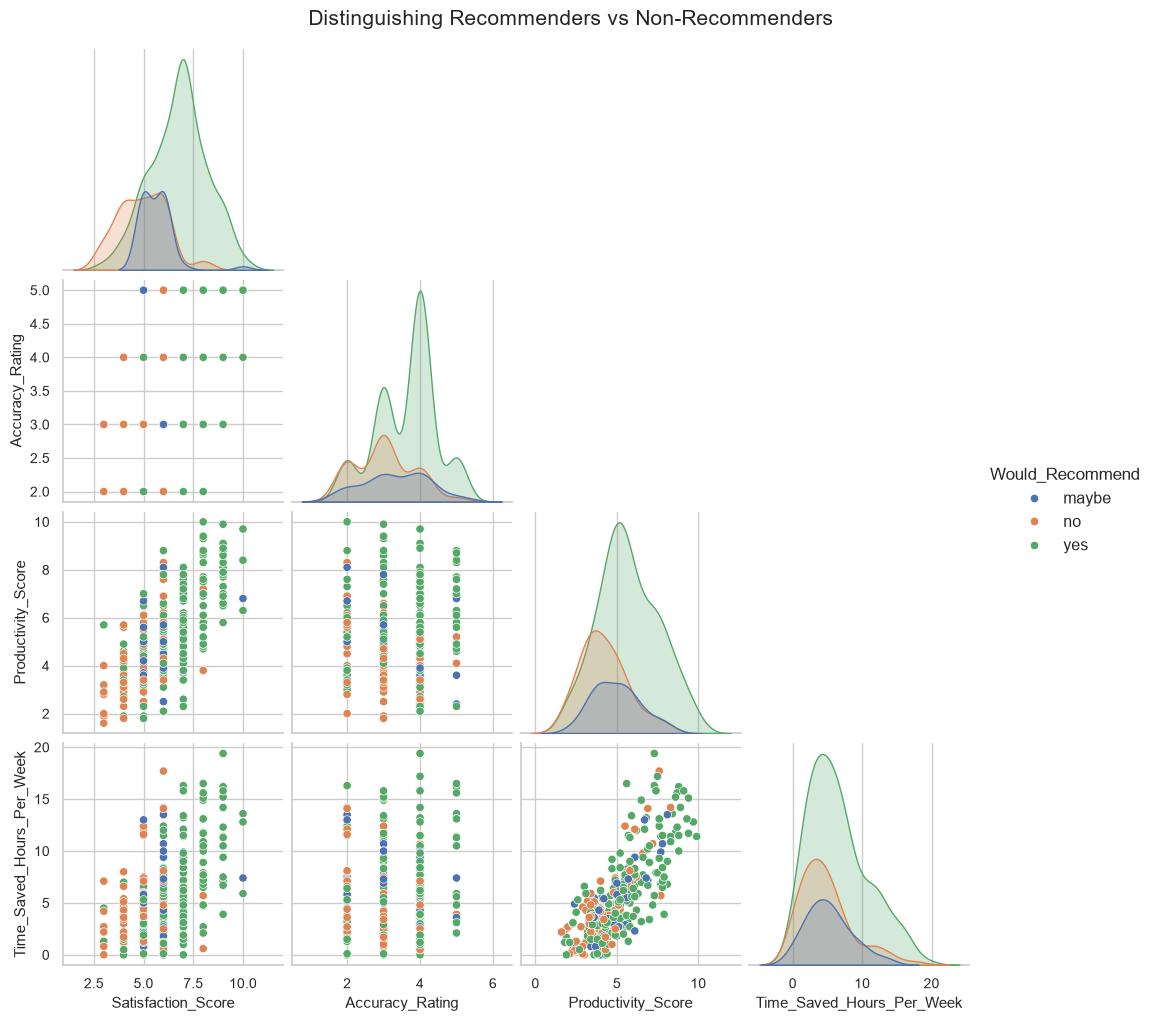

In [400]:
df_recommend = df.dropna(subset=['Would_Recommend'])

sns.pairplot(
    df_recommend,
    vars=['Satisfaction_Score', 'Accuracy_Rating', 'Productivity_Score', 'Time_Saved_Hours_Per_Week'], hue='Would_Recommend', 
    diag_kind='kde', 
    corner=True
)

plt.suptitle("Distinguishing Recommenders vs Non-Recommenders", y=1.02)

### Q10 : Are there signs of diminishing returns from increased AI usage?

Text(0.5, 1.0, 'Median Productivity Score by Daily Usage Hours')

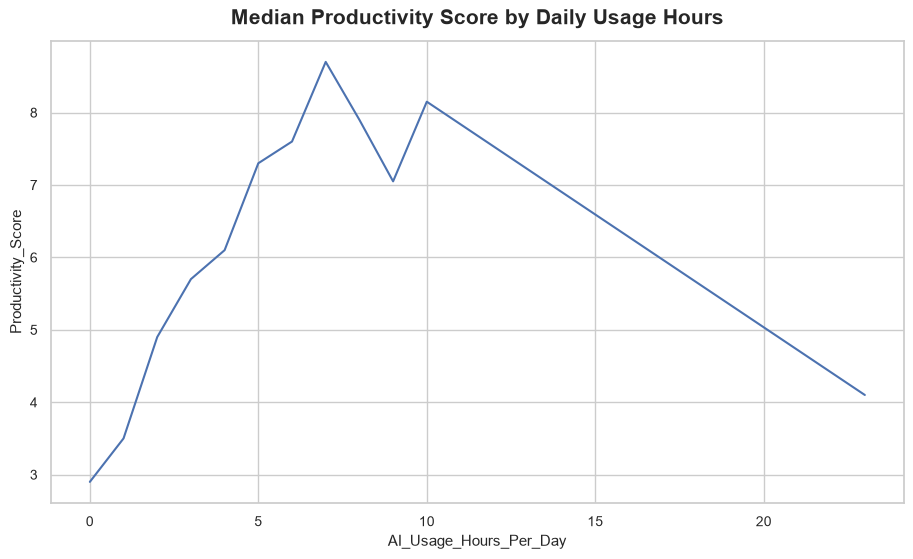

In [401]:
sns.lineplot(
    x='AI_Usage_Hours_Per_Day', 
    y='Productivity_Score', 
    data=df.round({'AI_Usage_Hours_Per_Day': 0}), 
    estimator=np.median, 
    errorbar=None
)

plt.title("Median Productivity Score by Daily Usage Hours")


### Q11 : Which user segments have high usage but weak outcomes?

In [402]:
high_usage_threshold = df['AI_Usage_Hours_Per_Day'].quantile(0.75)
low_prod_threshold = df['Productivity_Score'].quantile(0.25)

In [403]:
inefficient_users = df[
    (df['AI_Usage_Hours_Per_Day'] > high_usage_threshold)
    & 
    (df['Productivity_Score'] < low_prod_threshold)
]

print(f"Number of high-usage/low-productivity users: {len(inefficient_users)}")

if len(inefficient_users) > 0:
    print(inefficient_users['AI_Tool'].value_counts().head())

Number of high-usage/low-productivity users: 0
